# 03 — Baseline Segmentasi Otsu Global

## Tujuan dan batas analisis

**Pertanyaan:** polaritas *foreground* Otsu mana (`dark` vs `bright`) yang unggul pada data `train`, dan bagaimana performa *baseline* Otsu beserta pascapemrosesan morfologi (`M0`, `M1`, `M2`) pada `val` dibanding kontrol `all_foreground`?

**Artefak input:**
- `configs/otsu_raw.json`
- `results/otsu_train.csv`
- `results/otsu_val.csv`
- `results/otsu_morph_val.csv`
- `data/metadata/split_manifest.csv`
- Opsional: satu citra `train` untuk contoh visual *threshold* per citra dan histogram *grayscale*

**Batas eksekusi:** polaritas Otsu telah dipilih pada `train` dan dikunci di `configs/otsu_raw.json`. Notebook ini tidak memilih polaritas per citra menggunakan *ground truth* dan tidak menyentuh `test`.

In [1]:
%matplotlib inline

from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ebhi_dip import (
    EXPECTED_CATEGORIES,
    STAGES,
    category_macro_scores,
    category_score_table,
    compute_histogram_1d,
    configure_notebook_style,
    find_project_root,
    finish_figure,
    has_raw_dataset,
    load_otsu_config,
    load_reference_mask,
    load_rgb,
    load_split_manifest,
    morphology_variants,
    otsu_threshold_mask,
    overlap_scores,
    resolve_manifest_path,
    rgb_to_gray,
    sha256_bytes,
    uint8_bin_edges,
)

PROJECT_ROOT_OVERRIDE = None
DATA_ROOT_OVERRIDE = None
EXPORT_FIGURES = False
TRAIN_EXAMPLE_ID = "Normal/GT2000000-1-400-001"

ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
OTSU_CONFIG = load_otsu_config(ROOT)
RAW_AVAILABLE = has_raw_dataset(ROOT, data_root_override=DATA_ROOT_OVERRIDE)
configure_notebook_style()

source_files = {
    "otsu_config": ROOT / "configs/otsu_raw.json",
    "otsu_train": ROOT / "results/otsu_train.csv",
    "otsu_val": ROOT / "results/otsu_val.csv",
    "otsu_morph_val": ROOT / "results/otsu_morph_val.csv",
    "split_manifest": ROOT / "data/metadata/split_manifest.csv",
}
input_hashes_before = {name: sha256_bytes(path) for name, path in source_files.items()}

display(pd.Series(OTSU_CONFIG, name="otsu_raw_config").to_frame())

,otsu_raw_config
method,otsu
grayscale_conversion,RGB2GRAY
threshold_mode,per_image_otsu
foreground_polarity,dark
postprocessing,none
reference_threshold,128
polarity_selected_on,train
selection_metric,mean_category_dice
training_mean_category_dice,0.683372
split_sha256,ceeba8e282f77cdb78a9675618b3dcb6729fbc2339e2d1...


## 1. Pemilihan polaritas *foreground* pada subset `train`

Metode Otsu menghitung satu *threshold* intensitas `grayscale` per citra secara adaptif, tetapi arah *foreground* (`dark`: `gray <= thr` vs `bright`: `gray > thr`) ditetapkan satu kali secara global dari 1.535 citra `train`.

In [2]:
otsu_train = pd.read_csv(source_files["otsu_train"], encoding="utf-8-sig")
split_df = load_split_manifest(ROOT, verify=False)
train_cohort = split_df.loc[split_df["split"].eq("train")]
assert len(otsu_train) == 1535 and set(otsu_train["sample_id"]) == set(train_cohort["sample_id"])

train_long = pd.concat(
    [
        otsu_train[["sample_id", "category", f"{m}_dice", f"{m}_iou"]]
        .rename(columns={f"{m}_dice": "dice", f"{m}_iou": "iou"})
        .assign(method=m)
        for m in ("dark", "bright", "all_foreground")
    ],
    ignore_index=True,
)
train_macro = category_macro_scores(train_long, expected_categories=EXPECTED_CATEGORIES)
train_by_cat = category_score_table(train_long, expected_categories=EXPECTED_CATEGORIES)["dice"].unstack("method")
display(train_by_cat.round(4))

method,all_foreground,bright,dark
category,,,
Adenocarcinoma,0.7904,0.3359,0.7523
High-grade IN,0.8100,0.2654,0.8089
Low-grade IN,0.7838,0.4109,0.6923
Normal,0.7626,0.5237,0.5695
Polyp,0.6986,0.4073,0.6229
Serrated adenoma,0.7534,0.4094,0.6543


In [3]:
display(train_macro.round(4))

,mean_category_dice,mean_category_iou
method,,
all_foreground,0.7665,0.6312
bright,0.3921,0.2558
dark,0.6834,0.5316


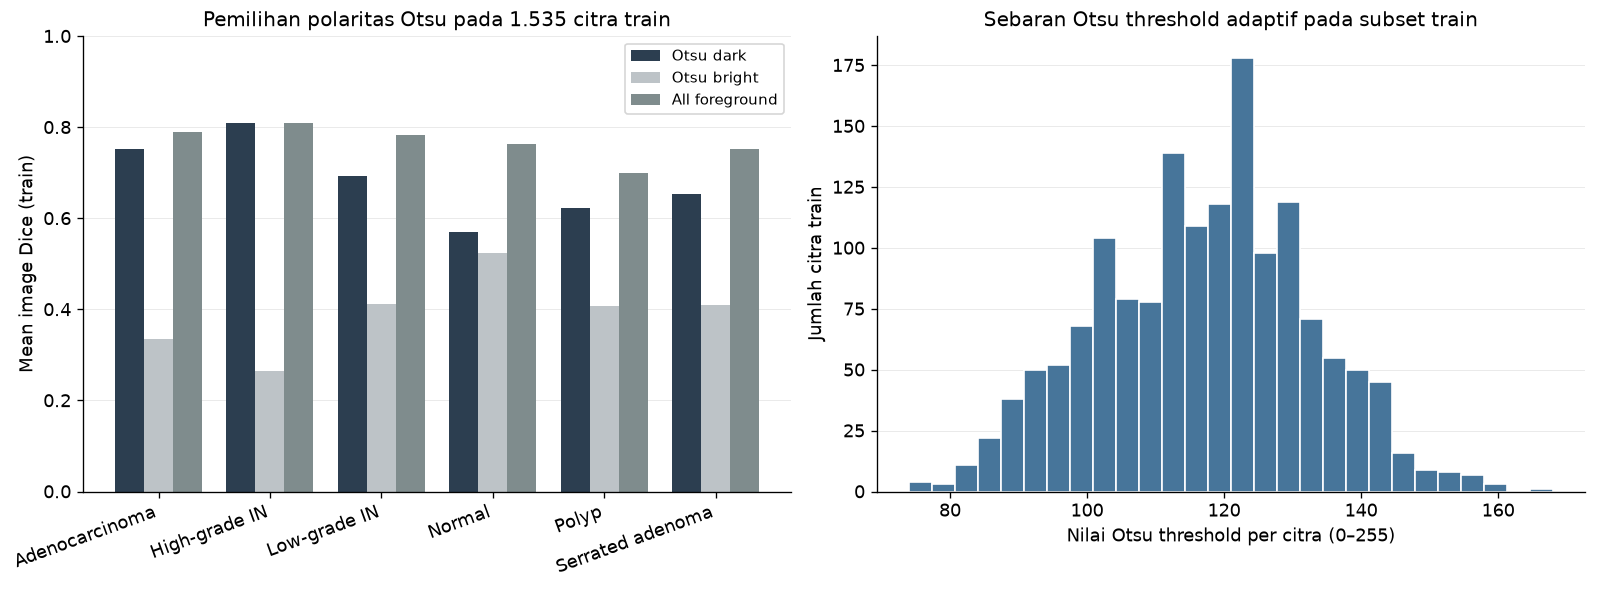

In [4]:
np.testing.assert_allclose(
    float(train_macro.loc["dark", "mean_category_dice"]),
    float(OTSU_CONFIG["training_mean_category_dice"]),
    rtol=0.0,
    atol=1e-12,
)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8), layout="constrained")
x = np.arange(len(EXPECTED_CATEGORIES))
w = 0.26
axes[0].bar(x - w, train_by_cat["dark"], width=w, color="#2C3E50", label="Otsu dark")
axes[0].bar(x, train_by_cat["bright"], width=w, color="#BDC3C7", label="Otsu bright")
axes[0].bar(x + w, train_by_cat["all_foreground"], width=w, color="#7F8C8D", label="All foreground")
axes[0].set_xticks(x, list(EXPECTED_CATEGORIES))
plt.setp(axes[0].get_xticklabels(), rotation=20, ha="right")
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel("Mean image Dice (train)")
axes[0].set_title("Pemilihan polaritas Otsu pada 1.535 citra train")
axes[0].legend(frameon=True, fontsize=8.8)
axes[0].grid(axis="y", color="#EAEAEA", linewidth=0.6)

axes[1].hist(otsu_train["otsu_threshold"], bins=28, color="#47759A", edgecolor="white")
axes[1].set_xlabel("Nilai Otsu threshold per citra (0–255)")
axes[1].set_ylabel("Jumlah citra train")
axes[1].set_title("Sebaran Otsu threshold adaptif pada subset train")
axes[1].grid(axis="y", color="#EAEAEA", linewidth=0.6)

export_target = (ROOT / "reports/figures/03_otsu_train_polarity.png") if EXPORT_FIGURES else None
finish_figure(fig, export_path=export_target)

**Makna hasil `train`.** Polaritas `dark` menghasilkan *equal-category mean* Dice `0.6834` dan mengungguli `bright` di seluruh kategori karena inti sel dan epitel terwarnai hematoksilin/eosin lebih gelap dibanding latar lumen putih. Polaritas ini dikunci sebagai `dark` untuk validasi.

## 2. Evaluasi *baseline* Otsu dan varian morfologi pada `val`

`otsu_val.csv` (evaluasi awal `M0`) direkonsiliasi terhadap `otsu_morph_val.csv` (`M0`, `M1`, `M2`, dan kontrol `all_foreground`) pada 372 citra validasi.

In [5]:
otsu_val = pd.read_csv(source_files["otsu_val"], encoding="utf-8-sig").sort_values("sample_id")
otsu_morph = pd.read_csv(source_files["otsu_morph_val"], encoding="utf-8-sig").sort_values("sample_id")
assert len(otsu_val) == 372 and len(otsu_morph) == 372
assert (otsu_val["sample_id"].to_numpy() == otsu_morph["sample_id"].to_numpy()).all()

np.testing.assert_allclose(otsu_val["otsu_dice"], otsu_morph["M0_dice"], rtol=0.0, atol=1e-12)
np.testing.assert_allclose(otsu_val["otsu_iou"], otsu_morph["M0_iou"], rtol=0.0, atol=1e-12)
np.testing.assert_allclose(otsu_val["otsu_threshold"], otsu_morph["otsu_threshold"], rtol=0.0, atol=1e-12)

val_long = pd.concat(
    [
        otsu_morph[["sample_id", "category", f"{m}_dice", f"{m}_iou"]]
        .rename(columns={f"{m}_dice": "dice", f"{m}_iou": "iou"})
        .assign(method=f"otsu_{m}" if m in STAGES else m)
        for m in (*STAGES, "all_foreground")
    ],
    ignore_index=True,
)
val_macro = category_macro_scores(val_long, expected_categories=EXPECTED_CATEGORIES)
val_by_cat = category_score_table(val_long, expected_categories=EXPECTED_CATEGORIES)["dice"].unstack("method")
display(val_by_cat[["otsu_M0", "otsu_M1", "otsu_M2", "all_foreground"]].round(4))

method,otsu_M0,otsu_M1,otsu_M2,all_foreground
category,,,,
Adenocarcinoma,0.7428,0.7439,0.7563,0.7821
High-grade IN,0.8091,0.8113,0.8246,0.8000
Low-grade IN,0.7069,0.7071,0.7111,0.7861
Normal,0.6535,0.6535,0.6494,0.7119
Polyp,0.6107,0.6162,0.6048,0.7010
Serrated adenoma,0.8164,0.8170,0.8266,0.8790


In [6]:
display(val_macro.loc[["otsu_M0", "otsu_M1", "otsu_M2", "all_foreground"]].round(4))

,mean_category_dice,mean_category_iou
method,,
otsu_M0,0.7232,0.5788
otsu_M1,0.7248,0.5811
otsu_M2,0.7288,0.5886
all_foreground,0.7767,0.6477


## 3. Contoh visual *threshold* per citra dan histogram *grayscale* (`train`)

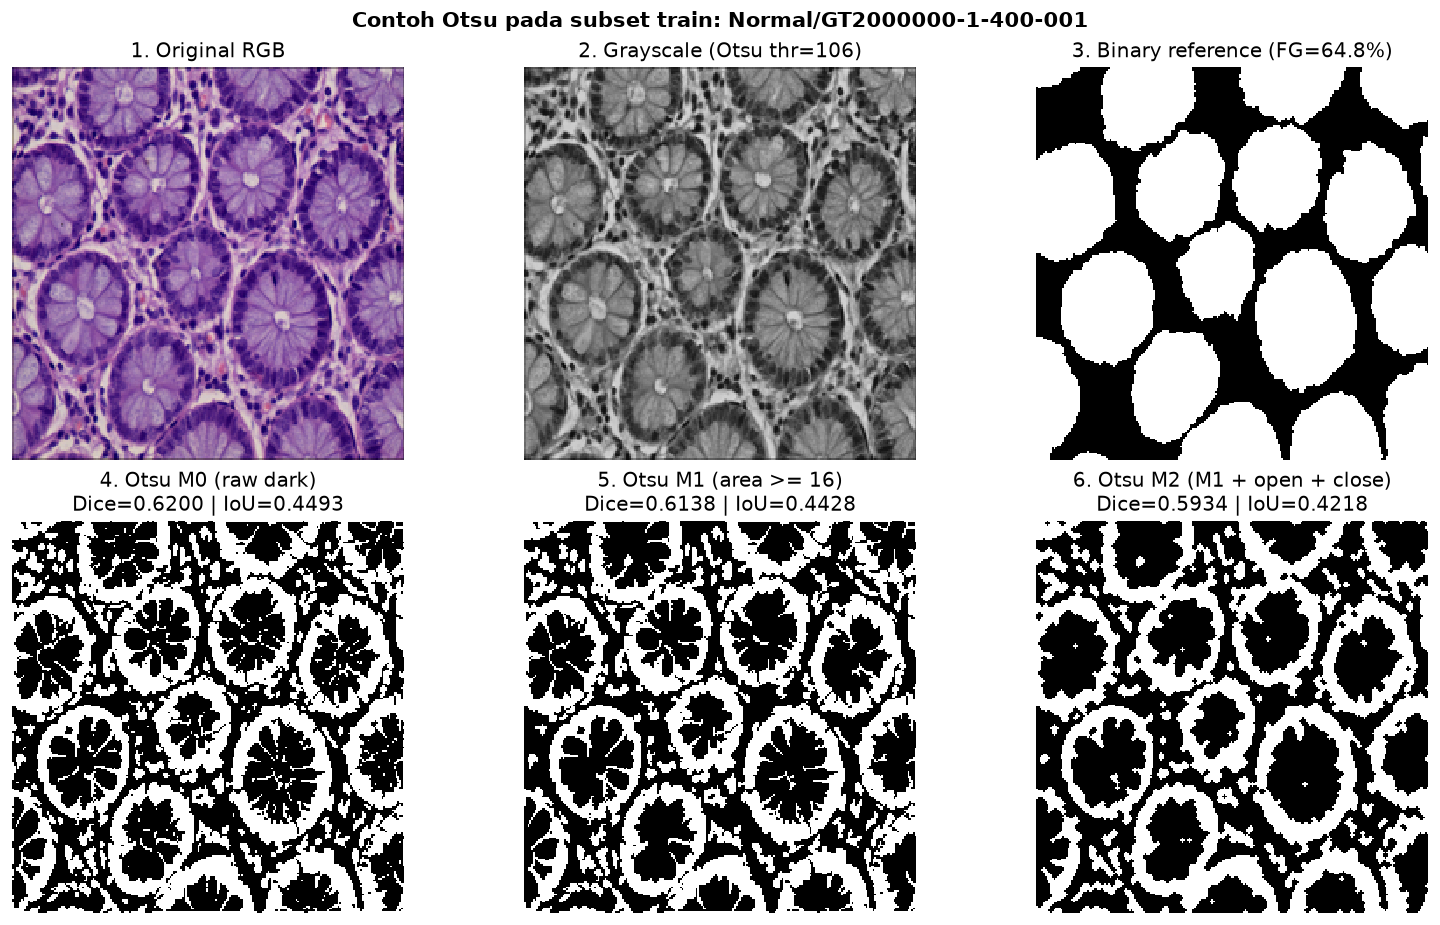

In [7]:
train_rec = split_df.loc[split_df["sample_id"].eq(TRAIN_EXAMPLE_ID)].iloc[0]
assert train_rec["split"] == "train"

if not RAW_AVAILABLE:
    display(
        Markdown(
            "> **Status citra mentah:** `data/raw/EBHI-SEG/` tidak tersedia; contoh visual Otsu pada citra `train` dilewati."
        )
    )
else:
    img = load_rgb(resolve_manifest_path(ROOT, train_rec["image_path"], data_root_override=DATA_ROOT_OVERRIDE))
    ref = load_reference_mask(resolve_manifest_path(ROOT, train_rec["mask_path"], data_root_override=DATA_ROOT_OVERRIDE))
    gray = rgb_to_gray(img)
    thr, raw_mask = otsu_threshold_mask(img, foreground_polarity=str(OTSU_CONFIG["foreground_polarity"]))
    variants = morphology_variants(raw_mask)

    fig, axes = plt.subplots(2, 3, figsize=(12.8, 7.6), layout="constrained")
    panels = [
        (img, "1. Original RGB", None),
        (gray, f"2. Grayscale (Otsu thr={thr:.0f})", "gray_u8"),
        (ref, f"3. Binary reference (FG={100*ref.mean():.1f}%)", "bin"),
        (variants["M0"], "4. Otsu M0 (raw dark)", "bin"),
        (variants["M1"], "5. Otsu M1 (area >= 16)", "bin"),
        (variants["M2"], "6. Otsu M2 (M1 + open + close)", "bin"),
    ]
    for ax, (arr, title, kind) in zip(axes.ravel(), panels):
        if kind is None:
            ax.imshow(arr, interpolation="nearest")
        elif kind == "gray_u8":
            ax.imshow(arr, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        else:
            d_val, i_val = overlap_scores(arr, ref)
            if "Otsu" in title:
                title = f"{title}\nDice={d_val:.4f} | IoU={i_val:.4f}"
            ax.imshow(arr, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(f"Contoh Otsu pada subset train: {TRAIN_EXAMPLE_ID}", fontweight="bold")
    export_target = (ROOT / "reports/figures/03_otsu_train_example_masks.png") if EXPORT_FIGURES else None
    finish_figure(fig, export_path=export_target)

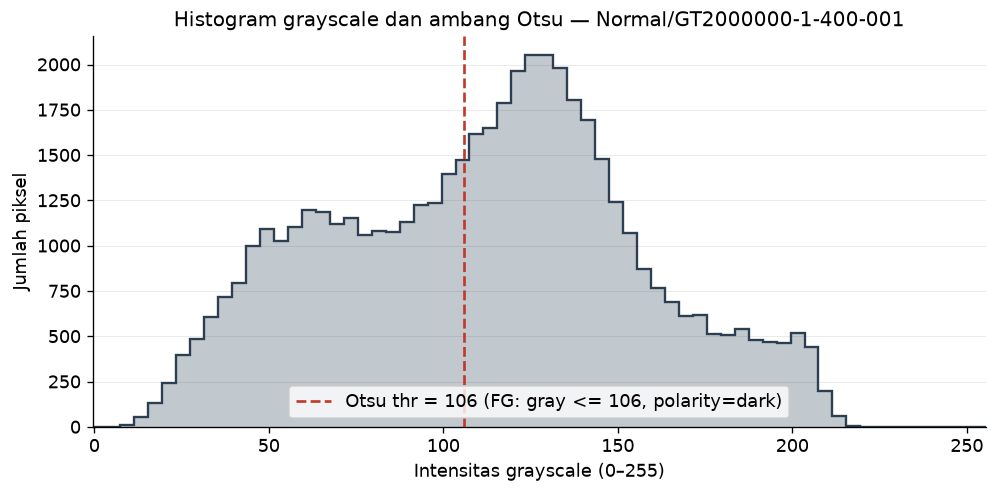

In [8]:
if RAW_AVAILABLE:
    h_gray = compute_histogram_1d(gray, uint8_bin_edges(64))
    fig_h, ax_h = plt.subplots(figsize=(8.2, 4.0), layout="constrained")
    ax_h.stairs(h_gray["heights"], h_gray["edges"], fill=True, alpha=0.30, color="#34495E")
    ax_h.stairs(h_gray["heights"], h_gray["edges"], color="#2C3E50", linewidth=1.4)
    ax_h.axvline(thr, color="#C0392B", linestyle="--", linewidth=1.6, label=f"Otsu thr = {thr:.0f} (FG: gray <= {thr:.0f}, polarity=dark)")
    ax_h.set_xlim(-0.5, 255.5)
    ax_h.set_xlabel("Intensitas grayscale (0–255)")
    ax_h.set_ylabel("Jumlah piksel")
    ax_h.set_title(f"Histogram grayscale dan ambang Otsu — {TRAIN_EXAMPLE_ID}")
    ax_h.legend(frameon=True)
    ax_h.grid(axis="y", color="#EAEAEA", linewidth=0.6)
    export_hist = (ROOT / "reports/figures/03_otsu_train_gray_hist.png") if EXPORT_FIGURES else None
    finish_figure(fig_h, export_path=export_hist)

## Ringkasan dan keterbatasan

- **Observasi:** pada kohort `val`, `otsu_M0` mencapai *equal-category mean* Dice `0.7232` (`IoU = 0.5788`), meningkat tipis menjadi `0.7288` (`IoU = 0.5886`) pada `otsu_M2`, tetapi masih berada di bawah kontrol `all_foreground` (`0.7767`).
- **Dugaan penyebab:** *threshold* intensitas tunggal pada `grayscale` memisahkan inti gelap dari latar terang, namun melewatkan sitoplasma/stroma pucat yang tetap termasuk dalam anotasi poligon kelenjar atau jaringan luas.
- **Langkah berikut:** memanfaatkan informasi kromatis H&E pada ruang warna fisik CIE Lab (`04_lab_kmeans.ipynb`).

In [9]:
input_hashes_after = {name: sha256_bytes(path) for name, path in source_files.items()}
assert input_hashes_after == input_hashes_before, "Artefak Otsu berubah saat notebook dijalankan."
print("Selesai: polaritas train dan skor validasi Otsu terverifikasi tanpa perubahan artefak.")

Selesai: polaritas train dan skor validasi Otsu terverifikasi tanpa perubahan artefak.
